<a href="https://colab.research.google.com/github/caroline-reges/Image-Identification-Using-Deep-Learning/blob/main/Deep%20Learning%20Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import packages

In [9]:
#keeps google colab connected to my drive
from google.colab import drive
drive.mount('/content/drive')

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load Data

In [2]:
images_path = "/content/drive/MyDrive/animals10/raw-img"

print(os.listdir(images_path))

['cane', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo', 'cavallo']


# Data cleaning and EDA, Data Preprocessing

Change my folder names from italian to english

In [6]:
translate = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
             "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
             "ragno": "spider", "scoiattolo": "squirrel"}
for italian, english in translate.items():
    old_path = os.path.join(images_path, italian) #create old folder path
    new_path = os.path.join(images_path, english) #create new folder path

    if os.path.exists(old_path): #I can run this code again and it won't give me errors
        os.rename(old_path, new_path) #rename folder


['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


Check class distribution

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'dog'),
  Text(1, 0, 'elephant'),
  Text(2, 0, 'butterfly'),
  Text(3, 0, 'chicken'),
  Text(4, 0, 'cat'),
  Text(5, 0, 'cow'),
  Text(6, 0, 'sheep'),
  Text(7, 0, 'spider'),
  Text(8, 0, 'squirrel'),
  Text(9, 0, 'horse')])

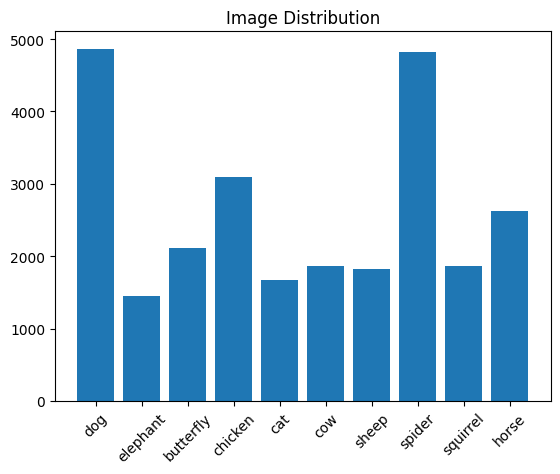

In [15]:
image_count = []

for folder in os.listdir(images_path):
  #count number of images in each folder
  folder_path = os.path.join(images_path, folder)
  num_images = len(os.listdir(folder_path))

  image_count.append((folder, num_images))

dist_df = pd.DataFrame(image_count, columns=['Folder', 'Count'])

plt.bar(dist_df['Folder'], dist_df['Count'])
plt.title('Image Distribution')
plt.xticks(rotation=45)
